In [2]:
from bs4 import BeautifulSoup
import requests
import pandas as pd

<!DOCTYPE html>
<html class="no-js" data-root="/home/bbr/build" data-version="klecko-" lang="en">
 <head>
  <meta charset="utf-8"/>
  <meta content="ie=edge" http-equiv="x-ua-compatible"/>
  <meta content="width=device-width, initial-scale=1.0, maximum-scale=2.0" name="viewport"/>
  <link href="https://cdn.ssref.net/req/202610191" rel="dns-prefetch"/>
  <script>
   /* https://docs.osano.com/hc/en-us/articles/22469433444372-Google-Consent-Mode-v2  */
  window.dataLayer = window.dataLayer ||[];
      function gtag(){dataLayer.push(arguments);}
      gtag('consent','default',{
        'ad_storage':'denied',
        'analytics_storage':'denied',
        'ad_user_data':'denied',
        'ad_personalization':'denied',
        'personalization_storage':'denied',
        'functionality_storage':'granted',
        'security_storage':'granted',
        'wait_for_update': 500
      });
      gtag("set", "ads_data_redaction", true);
  </script>
  <script src="https://cmp.osano.com/16CGnCU8UtNhM14s
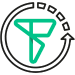
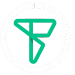

In [5]:
url = 'https://www.basketball-reference.com/awards/mvp.html'
html_doc = requests.get(url)
soup = BeautifulSoup(html_doc.text,'html.parser')
print(soup.prettify())

In [30]:
tbl = soup.table

In [115]:
headers = []
for header in tbl.find_all('tr')[1].find_all('th'):
    hd = header.get_text(strip=True)
    if hd not in ['Lg','Voting']:
        headers.append(hd)
headers = headers[:-2]
mvp_df = pd.DataFrame(columns = headers)
mvp_df

for row in tbl.find_all('tr')[2:]:
    tmp = row.get_text(separator=',',strip=True).split(',')
    tmp[0] = tmp[0][:4]
    tmp.remove('(')
    tmp.remove(')')
    tmp.remove('V')
    tmp.remove('NBA')
    tmp = tmp[:-2]
    if tmp[0] == '1979':
        break
    mvp_df.loc[len(mvp_df)] = tmp 

In [116]:
mvp_df

,Season,Player,Age,Tm,G,MP,PTS,TRB,AST,STL,BLK,FG%,3P%,FT%
0,2025,Shai Gilgeous-Alexander,27,OKC,68,33.2,31.1,4.3,6.6,1.4,0.8,.553,.386,.879
1,2024,Shai Gilgeous-Alexander,26,OKC,76,34.2,32.7,5.0,6.4,1.7,1.0,.519,.375,.898
2,2023,Nikola JokiÄ,28,DEN,79,34.6,26.4,12.4,9.0,1.4,0.9,.583,.359,.817
3,2022,Joel Embiid,28,PHI,66,34.6,33.1,10.2,4.2,1.0,1.7,.548,.330,.857
4,2021,Nikola JokiÄ,26,DEN,74,33.5,27.1,13.8,7.9,1.5,0.9,.583,.337,.810
5,2020,Nikola JokiÄ,25,DEN,72,34.6,26.4,10.8,8.3,1.3,0.7,.566,.388,.868
6,2019,Giannis Antetokounmpo,25,MIL,63,30.4,29.5,13.6,5.6,1.0,1.0,.553,.304,.633
7,2018,Giannis Antetokounmpo,24,MIL,72,32.8,27.7,12.5,5.9,1.3,1.5,.578,.256,.729
8,2017,James Harden,28,HOU,72,35.4,30.4,5.4,8.8,1.8,0.7,.449,.367,.858
9,2016,Russell Westbrook,28,OKC,81,34.6,31.6,10.7,10.4,1.6,0.4,.425,.343,.845
